In [1]:
import pandas as pd
import numpy as np
import os
from glob import glob
from sklearn.metrics import roc_curve, auc, balanced_accuracy_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from scipy.optimize import brentq
from scipy.interpolate import interp1d
import itertools


In [2]:
def plot_confusion_matrix(labels, preds, classes=("Real", "Fake"),
                          normalize=True,
                          cmap=plt.cm.Blues,
                          ax=None):
    
    cm = confusion_matrix(labels, preds)

    if normalize:
        cm = cm.astype('float') / np.maximum(cm.sum(axis=1)[:, np.newaxis], 1)

    if ax is None:
        fig, ax = plt.subplots(figsize=(3, 3))

    im = ax.imshow(cm, interpolation='nearest', cmap=cmap,
                   vmin=0, vmax=1 if normalize else None)

    tick_marks = np.arange(len(classes))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(classes, rotation=45)
    ax.set_yticklabels(classes)

    threshold = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        text = f"{cm[i, j]*100:.2f}%" if normalize else f"{cm[i, j]:d}"
        ax.text(j, i, text,
                ha="center",
                color="white" if cm[i, j] > threshold else "black")

    ax.set_ylabel('True label')
    ax.set_xlabel('Predicted label')

    return cm

def compute_cllr(scores, labels):
    scores = np.array(scores)
    labels = np.array(labels)
    tar = scores[labels == 1]
    non = scores[labels == 0]
    c1 = np.mean(np.log2(1 + np.exp(-tar)))
    c2 = np.mean(np.log2(1 + np.exp(non)))
    return (c1 + c2) / 2
    
def print_metrics(scores, labels, threshold=0):
    fpr, tpr, thres = roc_curve(labels, scores)
    rocauc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_func = interp1d(fpr, fnr)
    eer = brentq(lambda x: eer_func(x) - x, 0., 1.)
    cllr = compute_cllr(scores, labels)
    
    preds = (scores >= threshold).astype(int)
    
    bacc = balanced_accuracy_score(preds, labels)
    acc = accuracy_score(preds, labels)
    prec = precision_score(labels, preds)
    rec = recall_score(labels, preds)
    f1 = f1_score(labels, preds)

    return rocauc, eer, cllr, bacc, acc, prec, rec, f1

def analyze_ensemble(all_logLR, labels, threshold=0):
    rocauc, eer, cllr, bacc, acc, prec, rec, f1 = print_metrics(all_logLR, labels, threshold)
    
    header = f"{'AUC%':>8} {'EER%':>8} {'Cllr':>8} | {'B.Acc.':>8} {'Acc.':>8} {'Prec.':>8} {'Recall':>8} {'F1':>8}"
    print(header)
    print(f"{rocauc*100:>8.2f} "
          f"{eer*100:>8.2f} "
          f"{cllr:>8.4f} |"
          f"{bacc*100:>8.2f} "
          f"{acc*100:>8.2f} "
          f"{prec*100:>8.2f} "
          f"{rec*100:>8.2f} "
          f"{f1*100:>8.2f}")

    preds = (all_logLR >= threshold).astype(int)

    # --- new: side-by-side ROC (left) + CM (right)
    fig, (ax_roc, ax_cm) = plt.subplots(1, 2, figsize=(6, 3))

    fpr, tpr, _ = roc_curve(labels, all_logLR)
    ax_roc.plot(fpr, tpr)
    ax_roc.plot([0, 1], [0, 1], linestyle='--')
    ax_roc.set_xlabel('FPR')
    ax_roc.set_ylabel('TPR')
    ax_roc.set_title(f'ROC (AUC={rocauc:.3f})')

    plot_confusion_matrix(labels, preds, ax=ax_cm)

    plt.tight_layout()


# ASVspoof 2019

In [4]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/5_experts"
specific_path = 'Cset_ASV19_pooled_50_dev_eval'
#specific_path = 'Cset_ASV15_no_pool_10'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))
#attack_ids = attack_ids[0, :]

# Compute individual logLR
unique_attacks = np.unique(attack_ids)
mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv19/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_50_dev_eval


,-,A01,A02,A03,A04,A07,A08,A09,A10,A11,A12
Exp 0,-0.00,-0.01,0.03,0.02,-0.02,0.03,0.00,0.03,0.00,0.01,0.00
Exp 1,-0.10,0.05,0.19,0.30,-0.20,-0.18,0.13,0.24,-0.16,0.08,-0.25
Exp 2,-0.39,0.04,-0.17,0.71,-0.37,0.27,0.61,1.03,0.06,0.20,-0.10
Exp 3,-0.49,-0.77,-0.44,0.63,1.77,-0.32,0.01,1.25,-0.28,1.52,2.09
Exp 4,-0.09,0.60,0.17,0.31,-0.08,0.06,0.44,0.04,-0.10,-0.05,-0.11


### Ensemble performance - SUM LLR:

    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   88.86    19.76   0.6381 |   64.57    71.64    97.69    68.74    80.70



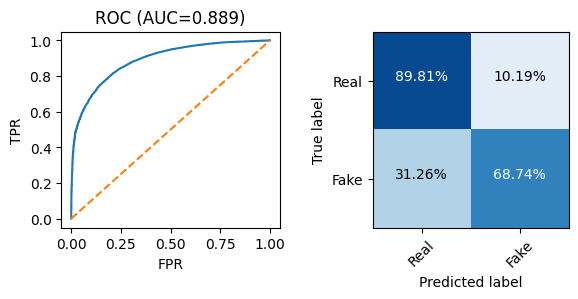

In [5]:
# Print ensemble performance metrics & confusion matrix
sum_logLR_scores = np.sum(logLR_scores, axis=0)  # sum expert contributions
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()

### MAX instead of SUM:

    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   85.22    22.22   0.8552 |   66.23    78.80    95.49    79.15    86.55


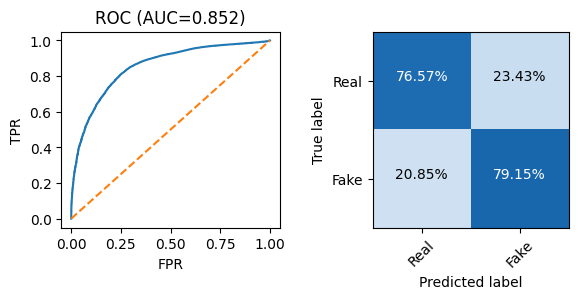

In [6]:
max_logLR_scores = np.max(logLR_scores, axis=0)  # take the max expert LLR for each test sample 
analyze_ensemble(max_logLR_scores, labels, threshold=0.3)

### Gating network 4 weighted sum:

    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   85.34    21.54   0.9072 |   64.98    75.51    96.14    74.59    84.01



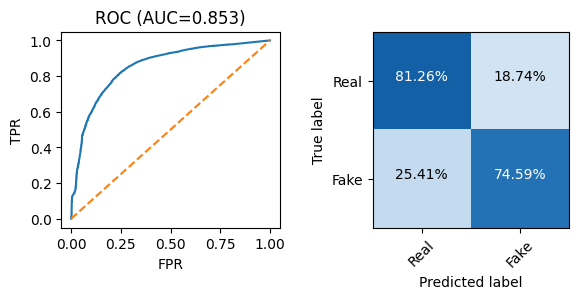

In [7]:
moe_path = "/home/smg/v-viola/moe_antideepfake/results/MoE/asv19/TargetCheck/ALL/MoE_Way3_Mix_Frozen_5Exp"
score_txt_path = os.path.join(moe_path, 'scores.txt')

identifiers, scores, labels = [], [], []
with open(score_txt_path, 'r') as fh:
    for line in fh:
        f, pred, lab = line.strip().split()
        pred = float(pred.strip('[]'))  # remove brackets
        lab = float(lab.strip('[]'))    # just in case labels also have them
        identifiers.append(f)
        scores.append(pred)
        labels.append(lab)

scores = np.array(scores, dtype=float)
labels = np.array(labels, dtype=float)
analyze_ensemble(scores, labels, threshold=0.15)
print()

## ASVspoof 5

/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_50

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   60.76    42.30   1.0282 |   55.25    44.52    86.97    35.99    50.91



,A01,A02,A03,A04,A05,A06,A07,A08,A09,A10,A11,A12,A14,A17,A19,A21,A22,A28,A29,bonafide
Exp 0,0.00,0.00,0.01,0.00,0.00,0.01,0.02,0.02,0.02,0.02,0.01,-0.02,-0.01,0.01,-0.01,0.02,0.01,0.01,0.01,0.01
Exp 1,0.27,0.32,0.31,0.19,0.25,0.28,0.46,0.21,0.23,0.23,0.13,-0.33,0.08,0.11,-0.16,0.30,0.20,0.06,0.18,0.04
Exp 2,0.15,0.16,0.20,0.23,0.27,0.22,0.35,0.05,0.26,0.26,0.03,-0.36,0.23,0.06,-0.14,0.17,0.29,0.18,0.30,0.06
Exp 3,-0.73,-0.78,-0.74,-0.68,-0.68,-0.75,-0.81,-0.77,0.14,0.15,2.06,-0.17,-0.89,-0.57,-0.25,0.12,0.61,-0.41,-0.57,-0.57
Exp 4,-0.19,-0.24,-0.22,-0.25,-0.30,-0.29,-0.29,-0.13,0.17,0.16,-0.10,-0.13,-0.35,-0.18,-0.13,0.01,0.18,-0.13,-0.24,-0.06


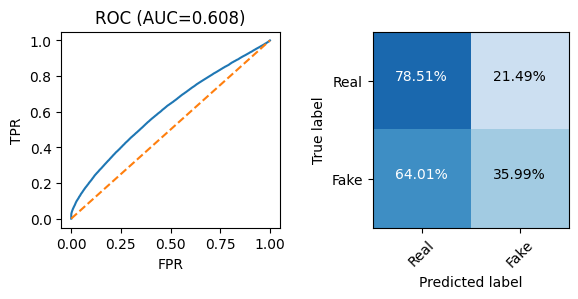

In [37]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/asv5/experts_trained_on_mix/CMLG/5_experts"
specific_path = 'Cset_ASV19_pooled_50'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

# SpoofCeleb

/home/smg/v-viola/moe_antideepfake/results/Ensemble/sc/experts_trained_on_mix/CMLG/5_experts/Cset_ASV19_pooled_50

Ensemble performance (PLAIN SUM):
    AUC%     EER%     Cllr |   B.Acc.     Acc.    Prec.   Recall       F1
   68.23    36.44   1.0667 |   52.57    28.90    98.47    25.21    40.14



,a00,a01,a02,a03,a04,a05,a06,a07,a08,a09,...,a14,a15,a16,a17,a18,a19,a20,a21,a22,a23
Exp 0,0.01,0.00,0.01,0.01,0.01,0.00,0.00,-0.02,0.01,0.01,...,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01
Exp 1,0.31,0.14,0.11,0.16,0.14,0.05,0.22,-0.04,0.16,0.26,...,0.33,0.32,0.31,0.33,0.32,0.31,0.31,0.32,0.35,0.30
Exp 2,-0.06,0.24,0.39,0.19,0.21,0.00,-0.22,-0.05,0.24,0.05,...,0.42,-0.06,-0.06,-0.06,-0.06,-0.05,-0.05,-0.05,-0.03,-0.20
Exp 3,-1.10,-0.74,0.83,-0.61,-0.62,-1.16,-0.97,-1.03,-0.98,-0.86,...,-0.94,-1.10,-1.10,-1.10,-1.10,-1.10,-1.10,-1.10,-1.10,-1.09
Exp 4,-0.36,0.18,0.21,0.20,0.08,0.08,-0.01,3.01,0.10,-0.05,...,-0.10,-0.36,-0.36,-0.35,-0.36,-0.36,-0.36,-0.35,-0.34,-0.35


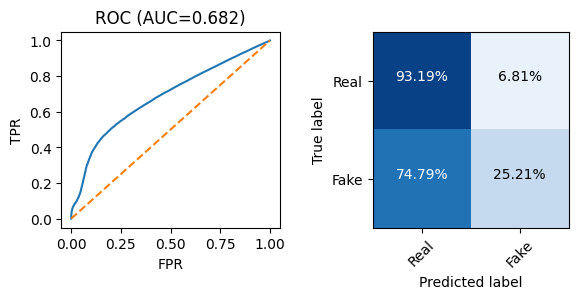

In [26]:
rootpath = "/home/smg/v-viola/moe_antideepfake/results/Ensemble/sc/experts_trained_on_mix/CMLG/5_experts"
specific_path = 'Cset_ASV19_pooled_50'

full_path = os.path.join(rootpath, specific_path)
print(full_path)

labels = np.load(os.path.join(full_path, "labels.npy"))
logLR_scores = np.load(os.path.join(full_path, "scores_per_expert.npy"))
attack_ids = np.load(os.path.join(full_path, "attack_ids.npy"))


# Print ensemble performance metrics & confusion matrix
print()
print("Ensemble performance (PLAIN SUM):")
sum_logLR_scores = np.sum(logLR_scores, axis=0)  
analyze_ensemble(sum_logLR_scores, labels, threshold=0)
print()


# Compute individual logLR
unique_attacks = np.unique(attack_ids)
#unique_attacks = unique_attacks[13:]

mean_scores_per_attack = {}
for attack in unique_attacks:
    mask = (attack_ids == attack)
    mask = mask.squeeze()  # (1, Nsamples) -> (Nsamples)
    mean_scores_per_attack[attack] = np.mean(logLR_scores[:, mask], axis=1)

# Visualize table
df = pd.DataFrame({a: mean_scores_per_attack[a] for a in unique_attacks})
df.index = [f"Exp {i}" for i in range(logLR_scores.shape[0])]
df.round(2)

# Paper plots (EER vs Cllr)

In [136]:
# X Labels
x_labels = [10, 50, 200, 500, 1000]
x_pos = range(len(x_labels))

# ---- EER (%) ----
pseudo_cmlg = [29.21, 27.56, 29.21, 28.98, 28.17]
pseudo_kde = [45, 43.13, 42.14, 42.66, 42.05]

asv15_cmlg = [32.12, 29.88, 26.93, 28.11, 27.37]
asv15_kde = [27.09, 25.24, 24.49, 23.36, 22.58]

asv19_no_pool_cmlg = [24.38, 21.06, 21.20, 21.87, 21.89]
asv19_no_pool_kde  = [23.69, 22.42, 20.60, 21.26, 23.58]

asv19_pool_cmlg = [20.07, 19.76, 21.06, 22.01, 22.26]
asv19_pool_kde  = [28.00, 22.42, 21.85, 22.52, 22.91]

# ---- Cllr ----
pseudo_cmlg_cllr = [3.00, 3.00, 3.00, 3.00, 3.00]
pseudo_kde_cllr = [3.00, 3.00, 3.00, 3.00, 3.00]

asv15_cmlg_cllr = [2.36, 1.50, 1.28, 1.37, 1.35]
asv15_kde_cllr = [3.00, 2.35, 1.78, 2.23, 2.44]

asv19_no_pool_cmlg_cllr = [2.05, 1.76, 1.61, 1.56, 1.59]
asv19_no_pool_kde_cllr  = [1.35, 1.40, 1.29, 1.29, 1.43]

asv19_pool_cmlg_cllr = [0.68, 0.63, 0.66, 0.68, 0.68]
asv19_pool_kde_cllr  = [0.82, 0.73, 0.72, 0.74, 0.74]

## Horizontal version

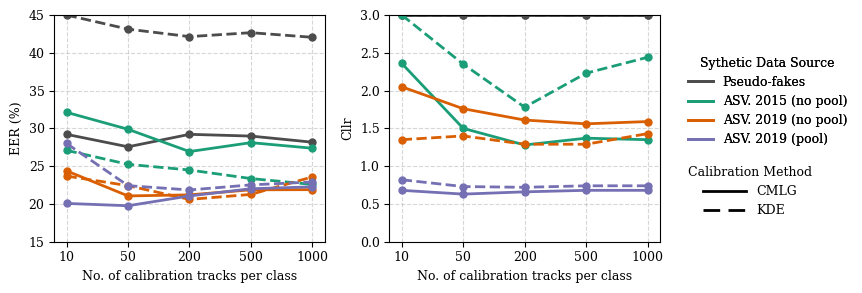

In [225]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# --- Style ---
mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 9,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

colors = {
    "pseudo": "#4C4C4C",
    "asv15": "#1B9E77",
    "asv19_np": "#D95F02",
    "asv19_p": "#7570B3",
}

x_labels = [10, 50, 200, 500, 1000]
x_pos = range(len(x_labels))

def plot_on_ax(ax, data_pairs, ylabel, ylim):
    for (y, style, color, label) in data_pairs:
        ax.plot(
            x_pos, y,
            linestyle=style,
            marker='o',
            linewidth=2,
            markersize=5,
            color=color,
            label=label
        )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(*ylim)
    ax.set_xlabel("No. of calibration tracks per class")
    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.5)


fig, axes = plt.subplots(1, 2, figsize=(8, 3))

# ---- Left: EER ----
plot_on_ax(axes[0], [
    (pseudo_cmlg, '-', colors["pseudo"], "PSEUDOF. CMLG"),
    (pseudo_kde,  '--', colors["pseudo"], "PSEUDOF. KDE"),
    (asv15_cmlg, '-', colors["asv15"], "ASV15 NP CMLG"),
    (asv15_kde,  '--', colors["asv15"], "ASV15 NP KDE"),
    (asv19_no_pool_cmlg, '-', colors["asv19_np"], "ASV19 NP CMLG"),
    (asv19_no_pool_kde,  '--', colors["asv19_np"], "ASV19 NP KDE"),
    (asv19_pool_cmlg, '-', colors["asv19_p"], "ASV19 P CMLG"),
    (asv19_pool_kde,  '--', colors["asv19_p"], "ASV19 P KDE"),
], ylabel="EER (%)", ylim=(15, 45))

# ---- Right: Cllr ----
plot_on_ax(axes[1], [
    (pseudo_cmlg_cllr, '-', colors["pseudo"], "PSEUDOF. CMLG"),
    (pseudo_kde_cllr,  '--', colors["pseudo"], "PSEUDOF. KDE"),
    (asv15_cmlg_cllr, '-', colors["asv15"], "ASV15 NP CMLG"),
    (asv15_kde_cllr,  '--', colors["asv15"], "ASV15 NP KDE"),
    (asv19_no_pool_cmlg_cllr, '-', colors["asv19_np"], "ASV19 NP CMLG"),
    (asv19_no_pool_kde_cllr,  '--', colors["asv19_np"], "ASV19 NP KDE"),
    (asv19_pool_cmlg_cllr, '-', colors["asv19_p"], "ASV19 P CMLG"),
    (asv19_pool_kde_cllr,  '--', colors["asv19_p"], "ASV19 P KDE"),
], ylabel="Cllr", ylim=(0, 3))

# --- Shared legend (from first axis) ---
from matplotlib.lines import Line2D

# --- Dataset legend (colors) ---
dataset_handles = [
    Line2D([0], [0], color=colors["pseudo"], lw=2, label="Pseudo-fakes"),
    Line2D([0], [0], color=colors["asv15"], lw=2, label="ASV. 2015 (no pool)"),
    Line2D([0], [0], color=colors["asv19_np"], lw=2, label="ASV. 2019 (no pool)"),
    Line2D([0], [0], color=colors["asv19_p"], lw=2, label="ASV. 2019 (pool)"),
]

# --- Method legend (linestyles) ---
method_handles = [
    Line2D([0], [0], color="black", lw=2, linestyle='-', label="CMLG"),
    Line2D([0], [0], color="black", lw=2, linestyle='--', dashes=(6,3), label="KDE"),
]

# Place them
leg1 = fig.legend(
    handles=dataset_handles,
    loc="center left",
    bbox_to_anchor=(0.85, 0.65),
    frameon=False,
    title="Sythetic Data Source"
)

leg2 = fig.legend(
    handles=method_handles,
    loc="center left",
    bbox_to_anchor=(0.85, 0.35),
    frameon=False,
    title="Calibration Method",
    handlelength=3.5
)

# Ensure both render
fig.add_artist(leg1)


plt.tight_layout(rect=[0, 0, 0.85, 1])  # leave space for legend
fig.savefig("/home/smg/v-viola/moe_antideepfake/figures/calibration_plots.pdf", format="pdf", bbox_inches="tight")
plt.show()


## Vertical version

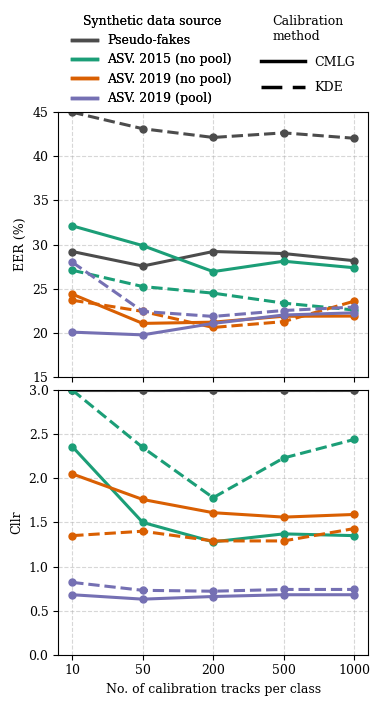

In [217]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D

# --- Style ---
mpl.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 9,
    "axes.labelsize": 9,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

# --- Colors ---
colors = {
    "pseudo": "#4C4C4C",
    "asv15": "#1B9E77",
    "asv19_np": "#D95F02",
    "asv19_p": "#7570B3",
}

# --- X axis ---
x_labels = [10, 50, 200, 500, 1000]
x_pos = range(len(x_labels))

# --- Plot helper ---
def plot_on_ax(ax, data_pairs, ylabel, ylim, show_xlabel=True):
    for (y, style, color, label) in data_pairs:
        ax.plot(
            x_pos, y,
            linestyle=style,
            marker='o',
            linewidth=2.2,
            markersize=5,
            color=color,
            label=label
        )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.set_ylim(*ylim)

    if show_xlabel:
        ax.set_xlabel("No. of calibration tracks per class")

    ax.set_ylabel(ylabel)
    ax.grid(True, linestyle="--", alpha=0.5)


# --- Figure: vertical layout ---
fig, axes = plt.subplots(2, 1, figsize=(4, 7), sharex=True)

# Reserve space for top legend
fig.subplots_adjust(
    top=0.885,
    hspace=0.05
)

# ---- Top: EER ----
plot_on_ax(axes[0], [
    (pseudo_cmlg, '-', colors["pseudo"], "PSEUDOF. CMLG"),
    (pseudo_kde,  '--', colors["pseudo"], "PSEUDOF. KDE"),
    (asv15_cmlg, '-', colors["asv15"], "ASV15 NP CMLG"),
    (asv15_kde,  '--', colors["asv15"], "ASV15 NP KDE"),
    (asv19_no_pool_cmlg, '-', colors["asv19_np"], "ASV19 NP CMLG"),
    (asv19_no_pool_kde,  '--', colors["asv19_np"], "ASV19 NP KDE"),
    (asv19_pool_cmlg, '-', colors["asv19_p"], "ASV19 P CMLG"),
    (asv19_pool_kde,  '--', colors["asv19_p"], "ASV19 P KDE"),
], ylabel="EER (%)", ylim=(15, 45), show_xlabel=False)

# ---- Bottom: Cllr ----
plot_on_ax(axes[1], [
    (pseudo_cmlg_cllr, '-', colors["pseudo"], "PSEUDOF. CMLG"),
    (pseudo_kde_cllr,  '--', colors["pseudo"], "PSEUDOF. KDE"),
    (asv15_cmlg_cllr, '-', colors["asv15"], "ASV15 NP CMLG"),
    (asv15_kde_cllr,  '--', colors["asv15"], "ASV15 NP KDE"),
    (asv19_no_pool_cmlg_cllr, '-', colors["asv19_np"], "ASV19 NP CMLG"),
    (asv19_no_pool_kde_cllr,  '--', colors["asv19_np"], "ASV19 NP KDE"),
    (asv19_pool_cmlg_cllr, '-', colors["asv19_p"], "ASV19 P CMLG"),
    (asv19_pool_kde_cllr,  '--', colors["asv19_p"], "ASV19 P KDE"),
], ylabel="Cllr", ylim=(0, 3), show_xlabel=True)


# --- Legends at top (balanced, no overlap, no over-wrapping) ---
dataset_handles = [
    Line2D([0], [0], color=colors["pseudo"], lw=2.5, label="Pseudo-fakes"),
    Line2D([0], [0], color=colors["asv15"], lw=2.5, label="ASV. 2015 (no pool)"),
    Line2D([0], [0], color=colors["asv19_np"], lw=2.5, label="ASV. 2019 (no pool)"),
    Line2D([0], [0], color=colors["asv19_p"], lw=2.5, label="ASV. 2019 (pool)"),
]

method_handles = [
    Line2D([0], [0], color="black", lw=2.5, linestyle='-', label="CMLG"),
    Line2D([0], [0], color="black", lw=2.5, linestyle='--', dashes=(6, 3), label="KDE"),
]

leg1 = fig.legend(
    handles=dataset_handles,
    loc="upper center",
    bbox_to_anchor=(0.36, 1.04),
    frameon=False,
    title="Synthetic data source",
    ncol=1,                 
)

leg2 = fig.legend(
    handles=method_handles,
    loc="upper center",
    bbox_to_anchor=(0.75, 1.04),
    frameon=False,
    title="Calibration\nmethod",
    ncol=1,       
    handlelength=3.5,
    labelspacing=1
)

fig.add_artist(leg1)


# --- Save ---
fig.savefig(
    "/home/smg/v-viola/moe_antideepfake/figures/calibration_plots_vertical.pdf",
    bbox_inches="tight"
)

plt.show()
